# 16. Conformal prediction intervals and out-of-distribution alarms

A prediction is more useful with a statement of how far it can be trusted. Split conformal prediction turns the residuals of a held-out calibration set into an interval with a stated coverage, without assuming a noise distribution. It says nothing about inputs unlike those used for calibration, so the lecture pairs it with the Mahalanobis distance, which flags a query that lies outside the training data even when each variable is within its range.

## Learning objectives

1. Implement split conformal prediction (`uncertainty.split_conformal_interval`) with the finite-sample quantile of the calibration residuals.
2. Measure the coverage on test data with skewed, non-Gaussian noise.
3. Compute the squared Mahalanobis distance (`uncertainty.mahalanobis_ood_score`) and check the identity for its mean over the training data.
4. Show that the Mahalanobis distance flags a query that is within the range of each variable but far from the training data.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Every trustworthy engineering surrogate requires an **input domain guardrail** and an **output uncertainty certificate**:
1. **Mahalanobis out-of-distribution (OOD) distance (Mahalanobis, 1936):** Given $N$ normal training states $\mathbf{X}_{\mathrm{train}} \in \mathbb{R}^{N \times d}$ with mean $\boldsymbol{\mu}$ and sample covariance $\boldsymbol{\Sigma} = \frac{1}{N-1}(\mathbf{X}_{\mathrm{train}} - \mathbf{1}\boldsymbol{\mu}^\top)^\top(\mathbf{X}_{\mathrm{train}} - \mathbf{1}\boldsymbol{\mu}^\top)$, the squared Mahalanobis distance of query $\mathbf{x}_* \in \mathbb{R}^d$ is:
   $$D_M^2(\mathbf{x}_*) = (\mathbf{x}_* - \boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1}(\mathbf{x}_* - \boldsymbol{\mu}) \tag{1.1}$$
   Using $\mathrm{Tr}(\mathbf{A}\mathbf{B}) = \mathrm{Tr}(\mathbf{B}\mathbf{A})$, the sample average of $D_M^2(\mathbf{x}_i)$ across the $N$ training observations satisfies an **exact distribution-free algebraic identity**:
   $$\frac{1}{N}\sum_{i=1}^N D_M^2(\mathbf{x}_i) = \frac{1}{N}\mathrm{Tr}\!\left(\mathbf{X}_c\boldsymbol{\Sigma}^{-1}\mathbf{X}_c^\top\right) = \frac{N-1}{N}\mathrm{Tr}(\mathbf{I}_d) = \frac{d(N-1)}{N} \tag{1.2}$$
2. **Distribution-free split conformal prediction (Vovk, Gammerman & Shafer 2005; Lei et al. 2018):** Given $n$ held-out calibration residuals $R_i = |y_i - \hat{f}(\mathbf{x}_i)|$ sorted as $R_{(1)} \le R_{(2)} \le \dots \le R_{(n)}$, setting the half-width $\hat{q}_{1-\alpha} = R_{(k)}$ with order statistic index $k = \lceil(n+1)(1-\alpha)\rceil$ guarantees finite-sample marginal coverage for *any* exchangeable data distribution:
   $$1 - \alpha \le \mathbb{P}\!\left(Y_{\mathrm{test}} \in \left[\hat{f}(\mathbf{X}_{\mathrm{test}}) - \hat{q}_{1-\alpha},\, \hat{f}(\mathbf{X}_{\mathrm{test}}) + \hat{q}_{1-\alpha}\right]\right) < 1 - \alpha + \frac{1}{n + 1} \tag{1.3}$$

In [2]:
heading("Demonstration 1: Split Conformal Coverage Guarantee on Skewed Exponential Sensor Noise")
rng = np.random.default_rng(2026)
n_cal, n_test = 300, 1000
x_cal = rng.uniform(0.0, 5.0, size=n_cal)
y_cal_pred = 2.5 * x_cal + 1.0
# Heavily skewed shifted-exponential noise (violates symmetric Gaussian textbook assumptions):
y_cal_true = y_cal_pred + (rng.exponential(scale=0.45, size=n_cal) - 0.45)

x_test = rng.uniform(0.0, 5.0, size=n_test)
y_test_pred = 2.5 * x_test + 1.0
y_test_true = y_test_pred + (rng.exponential(scale=0.45, size=n_test) - 0.45)

cp90 = uncertainty.split_conformal_interval(y_cal_true, y_cal_pred, y_test_pred, alpha=0.10)
cov90 = float(np.mean((y_test_true >= cp90["lower"]) & (y_test_true <= cp90["upper"])))
print(f"Split Conformal (Target 1 - alpha = 90.0%): half-width q_hat = +/-{cp90['q_hat']:.4f}")
print(f"Empirical out-of-sample test coverage (n_test = 1000)        = {cov90*100:.2f}%")
assert 0.87 <= cov90 <= 0.94


Demonstration 1: Split Conformal Coverage Guarantee on Skewed Exponential Sensor Noise
Split Conformal (Target 1 - alpha = 90.0%): half-width q_hat = +/-0.7357
Empirical out-of-sample test coverage (n_test = 1000)        = 92.90%


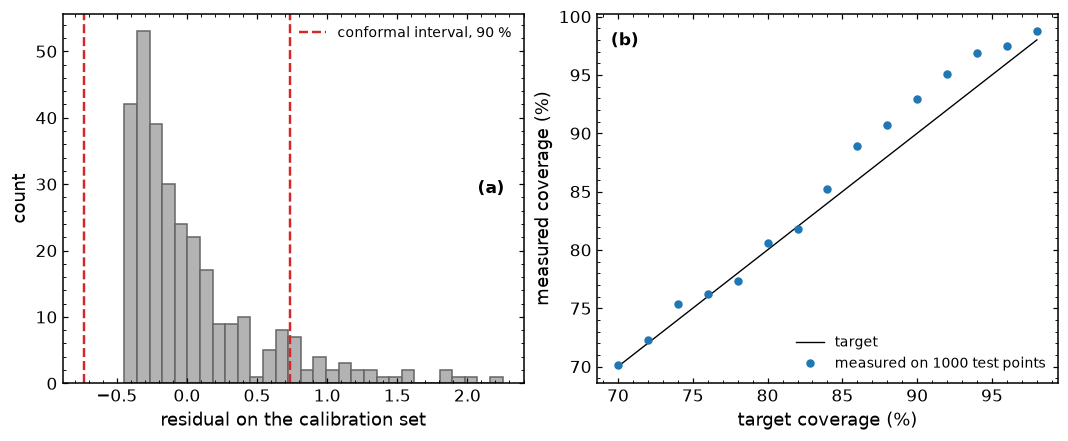

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
res_cal = y_cal_true - y_cal_pred
ax1.hist(res_cal, bins=30, color="0.7", edgecolor="0.4")
half_width = float(np.mean(cp90["upper"] - cp90["lower"])) / 2.0
ax1.axvline(-half_width, color="C3", ls="--"); ax1.axvline(half_width, color="C3", ls="--", label="conformal interval, 90 %")
ax1.set_xlabel("residual on the calibration set"); ax1.set_ylabel("count"); ax1.legend(fontsize=9, loc="upper right"); panel_label(ax1, "(a)", x=0.9, y=0.55)
alpha_line = np.linspace(0.02, 0.30, 15); cov_line = []
for alpha_v in alpha_line:
    cp_v = uncertainty.split_conformal_interval(y_cal_true, y_cal_pred, y_test_pred, alpha=float(alpha_v))
    cov_line.append(np.mean((y_test_true >= cp_v["lower"]) & (y_test_true <= cp_v["upper"])))
ax2.plot(100 * (1 - alpha_line), 100 * (1 - alpha_line), "k-", lw=0.9, label="target")
ax2.plot(100 * (1 - alpha_line), 100 * np.array(cov_line), "o", ms=4.5, label="measured on 1000 test points")
ax2.set_xlabel("target coverage (%)"); ax2.set_ylabel("measured coverage (%)"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 16.1.** (a) The residuals of the calibration set, which follow a skewed (shifted exponential) distribution, and the symmetric 90 % interval of split conformal prediction. (b) The coverage measured on the test set against the target coverage.

**What Demonstration 1 shows.** The noise is exponential, skewed and far from Gaussian, and no assumption about it was made. The interval uses only the 271st smallest of 300 calibration residuals, $k = \lceil 301 \times 0.90 \rceil$, and covers $92.9\ \%$ of 1000 new samples, above the target of $90\ \%$.

---

## 2. Numerical walkthrough
Let us verify the **exact Mahalanobis trace identity** Eq. (1.2) on $N = 80$ 3-dimensional reactor operating states $(T, P, x)$ and test a normal centroid query versus a runaway reactor excursion.

In [4]:
heading("Demonstration 2: Mahalanobis Trace Identity mean(D_M^2) = d*(N-1)/N & Runaway Alarm")
N_tr, d_feat = 80, 3
X_noc = rng.normal(loc=[370.0, 12.5, 0.65], scale=[8.0, 1.0, 0.08], size=(N_tr, d_feat))
d2_noc = uncertainty.mahalanobis_ood_score(X_noc, X_noc, reg=0.0)

expected_d2_mean = d_feat * (N_tr - 1.0) / N_tr
assert np.isclose(np.mean(d2_noc), expected_d2_mean, rtol=1e-12)
print(f"Mahalanobis sample mean D_M^2 = {np.mean(d2_noc):.8f} == Exact theoretical d*(N-1)/N = {expected_d2_mean:.8f}")

d2_centroid = float(uncertainty.mahalanobis_ood_score(X_noc, np.mean(X_noc, axis=0, keepdims=True))[0])
d2_runaway = float(uncertainty.mahalanobis_ood_score(X_noc, np.array([[460.0, 26.0, 0.95]]))[0])
print(f"Centroid query D_M^2 = {d2_centroid:.2e} | Runaway query (460 K, 26 bar) D_M^2 = {d2_runaway:.1f} >> chi^2_(3,0.99) = 11.34 (ood alarm)")
assert d2_centroid < 1e-12 and d2_runaway > 100.0


Demonstration 2: Mahalanobis Trace Identity mean(D_M^2) = d*(N-1)/N & Runaway Alarm
Mahalanobis sample mean D_M^2 = 2.96250000 == Exact theoretical d*(N-1)/N = 2.96250000
Centroid query D_M^2 = 0.00e+00 | Runaway query (460 K, 26 bar) D_M^2 = 314.5 >> chi^2_(3,0.99) = 11.34 (ood alarm)


**What Demonstration 2 shows.** As for Hotelling's $T^2$ in Lecture 9, the squared Mahalanobis distance of the training points averages exactly $d(N-1)/N = 3 \times 79/80 = 2.9625$. The runaway query has $D_M^2 = 314.5$, far above the $99\ \%$ limit of $11.34$.

---

## 3. Worked case study
Why is **covariance-aware Mahalanobis distance** more informative than coordinate-wise min/max box bounds ($x_{j,\min} \le x_{*,j} \le x_{j,\max}$)? Consider a vapor–liquid equilibrium reactor where pressure $P$ and temperature $T$ are tightly correlated along the saturation curve $P \approx 0.5 T - 170$.

In [5]:
heading("Demonstration 3: Correlation-Breaking OOD Detection — Mahalanobis vs. Univariate Box Bounds")
rng_corr = np.random.default_rng(123)
T_c = rng_corr.normal(360.0, 10.0, size=100)
P_c = 0.5 * T_c - 170.0 + rng_corr.normal(0.0, 0.25, size=100)
X_corr = np.column_stack([T_c, P_c])

# Off-diagonal query: T = 370 K (+1 sigma), P = 5.0 bar (-1 sigma), but correlation demands P(370 K) = 15.0 bar
x_query = np.array([[370.0, 5.0]])
z_axes = np.abs(x_query[0] - np.mean(X_corr, axis=0)) / np.std(X_corr, axis=0)
d2_query = float(uncertainty.mahalanobis_ood_score(X_corr, x_query)[0])
print("Univariate coordinate z-scores [|z_T|, |z_P|]:", np.round(z_axes, 2), "(Both < 1.5 sigma -> Passes univariate box checks)")
print(f"Multivariate Mahalanobis distance D_M^2      : {d2_query:.1f} >> chi^2_(2, 0.99) = 9.21 (out-of-distribution alarm)")
assert np.all(z_axes < 1.5) and d2_query > 400.0


Demonstration 3: Correlation-Breaking OOD Detection — Mahalanobis vs. Univariate Box Bounds
Univariate coordinate z-scores [|z_T|, |z_P|]: [1.03 1.21] (Both < 1.5 sigma -> Passes univariate box checks)
Multivariate Mahalanobis distance D_M^2      : 1910.0 >> chi^2_(2, 0.99) = 9.21 (out-of-distribution alarm)


query: 1.03 and 1.21 standard deviations on the two axes; squared Mahalanobis distance 1910; largest among the training points 9.9


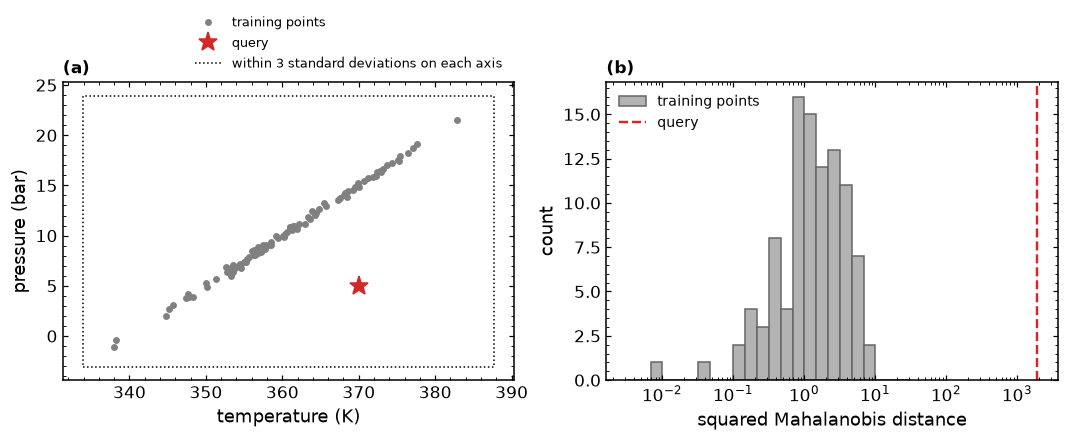

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(X_corr[:, 0], X_corr[:, 1], "o", ms=3.5, color="0.5", label="training points")
ax1.plot(x_query[0, 0], x_query[0, 1], "*", ms=13, color="C3", label="query")
mu_c = np.mean(X_corr, axis=0); sd_c = np.std(X_corr, axis=0)
ax1.plot(mu_c[0] + sd_c[0] * np.array([-3, 3, 3, -3, -3]), mu_c[1] + sd_c[1] * np.array([-3, -3, 3, 3, -3]), "k:", lw=1.0, label="within 3 standard deviations on each axis")
ax1.set_xlabel("temperature (K)"); ax1.set_ylabel("pressure (bar)"); ax1.legend(fontsize=8.5, loc="lower right", bbox_to_anchor=(1.0, 1.0)); ax1.set_title("(a)", loc="left", fontweight="bold")
d2_train = uncertainty.mahalanobis_ood_score(X_corr, X_corr)
ax2.hist(d2_train, bins=np.logspace(-2.5, 1.5, 25), color="0.7", edgecolor="0.4", label="training points")
ax2.axvline(d2_query, color="C3", ls="--", label="query")
ax2.set_xscale("log"); ax2.set_xlabel("squared Mahalanobis distance"); ax2.set_ylabel("count"); ax2.legend(fontsize=9, loc="upper left"); ax2.set_title("(b)", loc="left", fontweight="bold")
print(f"query: {z_axes[0]:.2f} and {z_axes[1]:.2f} standard deviations on the two axes; squared Mahalanobis distance {d2_query:.0f}; largest among the training points {np.max(d2_train):.1f}")
plt.show()

**Figure 16.2.** (a) Synthetic temperatures and pressures that lie close to a line, and a query that is within the range of each variable separately but far from the line. (b) The squared Mahalanobis distances of the training points and of the query.

**What Demonstration 3 shows.** Taken one at a time, the temperature and the pressure of the query are unremarkable: $1.03$ and $1.21$ standard deviations from their means. Taken together they are far outside the data, $D_M^2 = 1910$ against a limit of $9.21$, because in the training data the two variables are strongly correlated and the query combines them in a way that never occurred. Limits on single variables cannot see this.

---

## 4. What if: sensitivity to the parameters
Let us sweep the conformal confidence level $1 - \alpha \in \{80\%, 90\%, 95\%, 98\%\}$ and verify that empirical out-of-sample coverage tracks $1 - \alpha$ across the entire calibration curve.

In [7]:
heading("Demonstration 4: Conformal Confidence Level (1 - alpha) Sweep vs. Empirical Coverage")
print(f"{'Target 1 - alpha':>16s} | {'Order Index k':>13s} | {'Half-Width q_hat':>16s} | {'Empirical Test Coverage':>23s}")
print("-" * 76)
for alpha_v in [0.20, 0.10, 0.05, 0.02]:
    cp_v = uncertainty.split_conformal_interval(y_cal_true, y_cal_pred, y_test_pred, alpha=alpha_v)
    k_ord = int(np.ceil((n_cal + 1) * (1.0 - alpha_v)))
    emp_v = float(np.mean((y_test_true >= cp_v["lower"]) & (y_test_true <= cp_v["upper"])))
    print(f"{(1-alpha_v)*100:15.1f}% | {k_ord:13d} | {cp_v['q_hat']:16.4f} | {emp_v*100:22.2f}%")
    assert abs(emp_v - (1.0 - alpha_v)) < 0.04


Demonstration 4: Conformal Confidence Level (1 - alpha) Sweep vs. Empirical Coverage
Target 1 - alpha | Order Index k | Half-Width q_hat | Empirical Test Coverage
----------------------------------------------------------------------------
           80.0% |           241 |           0.4275 |                  80.60%
           90.0% |           271 |           0.7357 |                  92.90%
           95.0% |           286 |           1.1319 |                  97.10%
           98.0% |           295 |           1.6077 |                  98.80%


**What Demonstration 4 shows.** At every target level the coverage on the test set is at or above the target: $80.6$, $92.9$, $97.1$ and $98.8\ \%$ for targets of $80$, $90$, $95$ and $98\ \%$. The guarantee is that the coverage is at least $1 - \alpha$ on average over calibration sets; with 300 calibration points one realization differs from the target by a few points, here by up to $2.9$.

---

## Inside the algorithm
Below we compute the sorted conformal order statistic and the regularized Mahalanobis quadratic form in pure NumPy and verify digit-for-digit agreement with `uncertainty.split_conformal_interval` and `uncertainty.mahalanobis_ood_score`.

In [8]:
heading("Inside the Algorithm: By-Hand Conformal Quantile & Mahalanobis vs. the Library")
res_sorted = np.sort(np.abs(y_cal_true - y_cal_pred))
k_hand = int(np.ceil((n_cal + 1) * 0.90)) - 1
q_hat_hand = float(res_sorted[k_hand])
assert np.isclose(q_hat_hand, cp90["q_hat"], rtol=1e-15)

mu_c = np.mean(X_corr, axis=0)
cov_c = np.cov(X_corr, rowvar=False) + 1e-8 * np.eye(2)
diff_q = (x_query - mu_c).ravel()
d2_hand = float(diff_q @ np.linalg.solve(cov_c, diff_q))
print(f"by hand (pure NumPy): q_hat = {q_hat_hand:.6f}, D_M^2 = {d2_hand:.6f}")
print(f"library (engml_2_applied)     : q_hat = {cp90['q_hat']:.6f}, D_M^2 = {d2_query:.6f}")
assert np.isclose(d2_hand, d2_query, rtol=1e-14)


Inside the Algorithm: By-Hand Conformal Quantile & Mahalanobis vs. the Library
by hand (pure NumPy): q_hat = 0.735711, D_M^2 = 1909.993135
library (engml_2_applied)     : q_hat = 0.735711, D_M^2 = 1909.993135


## Exercises

1. **Verify a result.** Verify the **finite-sample conformal coverage theorem** Eq. (1.3) across 200 independent calibration/test splits ($n_{\mathrm{cal}} = 99, n_{\mathrm{test}} = 200, \alpha = 0.10$) under heavy-tailed Laplace noise: confirm that the mean marginal coverage across the 200 splits lies between $1 - \alpha = 0.900$ and $1 - \alpha + \frac{1}{n_{\mathrm{cal}}+1} = 0.910$.
2. **Find how it fails.** Audit the **covariate shift / non-exchangeability failure mode** of unguarded conformal prediction: suppose heteroscedastic sensor noise grows with temperature as $\sigma(T) = 0.05 + 0.02(T - 350)^2$, the calibration set is sampled inside $T_{\mathrm{cal}} \in [345, 355]\;\mathrm{K}$, and the plant drifts to an extrapolated regime $T_{\mathrm{shift}} \in [365, 375]\;\mathrm{K}$. Show that conformal coverage collapses below $30\%$, and verify that `mahalanobis_ood_score` flags $100\%$ of the shifted queries ($D_M^2 > 20$).
3. **Write it yourself.** Implement **normalized / locally-adaptive conformal prediction** `adaptive_conformal_interval(y_calib, y_pred_calib, sigma_calib, y_pred_test, sigma_test, alpha=0.10)` using studentized nonconformity scores $S_i = |y_i - \hat{y}_i| / \hat{\sigma}(\mathbf{x}_i)$, which produces variable-width intervals $\hat{y}_* \pm \hat{q}_{1-\alpha}\,\hat{\sigma}(\mathbf{x}_*)$. Verify on a heteroscedastic dataset that it maintains $\ge 88\%$ coverage while adapting interval widths to local noise scale.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: 200-Trial Verification of Finite-Sample Conformal Coverage Bounds")
rng_cp = np.random.default_rng(77)
covs_mc = []
for _ in range(200):
    r_cal = rng_cp.laplace(0.0, 1.0, size=99)
    r_te = rng_cp.laplace(0.0, 1.0, size=200)
    cp_m = uncertainty.split_conformal_interval(r_cal, np.zeros(99), np.zeros(200), alpha=0.10)
    covs_mc.append(float(np.mean((r_te >= cp_m["lower"]) & (r_te <= cp_m["upper"]))))
mean_cov_mc = float(np.mean(covs_mc))
print(f"Theoretical bounds: [0.9000, 0.9100] | 200-Trial Empirical Marginal Coverage = {mean_cov_mc:.4f}")
assert 0.895 <= mean_cov_mc <= 0.915


Exercise 1: 200-Trial Verification of Finite-Sample Conformal Coverage Bounds
Theoretical bounds: [0.9000, 0.9100] | 200-Trial Empirical Marginal Coverage = 0.8962
